<a href="https://colab.research.google.com/github/mansikaithwas/EDA-ipynb/blob/main/EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exploratory Data Analysis

Exploratory Data Analysis (EDA) is an approach that is used to analyze the data and discover trends, patterns, or check assumptions in data with the help of statistical summaries and graphical representations.

![image-2.png](attachment:image-2.png)

### Types of EDA

Univariate Analysis – In univariate analysis, we analyze or deal with only one variable at a time. The analysis of univariate data is thus the simplest form of analysis since the information deals with only one quantity that changes. It does not deal with causes or relationships and the main purpose of the analysis is to describe the data and find patterns that exist within it.

Bi-Variate analysis – This type of data involves two different variables. The analysis of this type of data deals with causes and relationships and the analysis is done to find out the relationship between the two variables.

Multivariate Analysis  – When the data involves three or more variables, it is categorized under multivariate.

![image.png](attachment:image.png)

Depending on the type of analysis we can also subcategorize EDA into two parts.

Non-graphical Analysis – In non-graphical analysis, we analyze data using statistical tools like mean median or mode or skewness

Graphical Analysis – In graphical analysis, we use visualizations charts to visualize trends and patterns in the data  

In this tutorial we will be exploring one of the important thread of machine learning, EDA (Exploratory Data Analysis) in which we will cover:

Loading of the dataset

Data Cleaning

Mean and Standard Deviation of Data

Checking for Null values and Data Types

Pandas EDA Important Functions

Visualise the frequency distribution of independent and dependent variables using histograms

Data Normalization

Visualise the linearity of independent and dependent variables using scatter plots

Visualise the correlation between independent and dependent variables using Heat Map


### About the Dataset:

This dataset has data collected from New York, California and Florida about 50 business Startups "17 in each state". The variables used in the dataset are Profit, R&D spending, Administration Spending, and Marketing Spending.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Data Cleaning
Import Data from CSV
Here we use Pandas library to see our data in a clean manner. We preprocess our data by removing unwanted data.

In [ ]:
data = pd.read_csv('C:/Users/jainr/OneDrive/Desktop/Deloitte Project_EDA/Deloitte Project_EDA/Rishi/50_Startups.csv')

In [ ]:
data

,R&D Spend,Administration,Marketing Spend,State,Profit
0,165349.20,136897.80,471784.10,New York,192261.83
1,162597.70,151377.59,443898.53,California,191792.06
2,153441.51,101145.55,407934.54,Florida,191050.39
3,144372.41,118671.85,383199.62,New York,182901.99
4,142107.34,91391.77,366168.42,Florida,166187.94
5,131876.90,99814.71,362861.36,New York,156991.12
6,134615.46,147198.87,127716.82,California,156122.51
7,130298.13,145530.06,323876.68,Florida,155752.60
8,120542.52,148718.95,311613.29,New York,152211.77
9,123334.88,108679.17,304981.62,California,149759.96


In [ ]:
data.head(3)

,R&D Spend,Administration,Marketing Spend,State,Profit
0,165349.20,136897.80,471784.10,New York,192261.83
1,162597.70,151377.59,443898.53,California,191792.06
2,153441.51,101145.55,407934.54,Florida,191050.39


In [ ]:
data.shape

(50, 5)

In [ ]:
data.columns

Index(['R&D Spend', 'Administration', 'Marketing Spend', 'State', 'Profit'], dtype='object')

In [ ]:
headers = np.array(data.columns)

In [ ]:
headers

array(['R&D Spend', 'Administration', 'Marketing Spend', 'State',
       'Profit'], dtype=object)

In [ ]:
data.memory_usage(deep=True)

Index               132
R&D Spend           400
Administration      400
Marketing Spend     400
State              2868
Profit              400
dtype: int64

#### Query Function

In [ ]:
n=data.query(" Administration > 130000 & Profit > 150000")

In [ ]:
n

,R&D Spend,Administration,Marketing Spend,State,Profit
0,165349.20,136897.80,471784.10,New York,192261.83
1,162597.70,151377.59,443898.53,California,191792.06
6,134615.46,147198.87,127716.82,California,156122.51
7,130298.13,145530.06,323876.68,Florida,155752.60
8,120542.52,148718.95,311613.29,New York,152211.77


#### Unique and nUnique function

In [ ]:
data.State.unique()

array(['New York', 'California', 'Florida'], dtype=object)

In [ ]:
data.State.nunique()

3

#### value_count Function

In [ ]:
data.State.value_counts()

State
New York      17
California    17
Florida       16
Name: count, dtype: int64

#### Groupby Function

In [ ]:
data.groupby("State")['Profit'].sum()

State
California    1766387.98
Florida       1900384.39
New York      1933859.59
Name: Profit, dtype: float64

#### Rename Function

In [ ]:
df1=data.rename(columns = {"R&D Spend": "R&D", "Marketing Spend": "Marketing"})

In [ ]:
df1

,R&D,Administration,Marketing,State,Profit
0,165349.20,136897.80,471784.10,New York,192261.83
1,162597.70,151377.59,443898.53,California,191792.06
2,153441.51,101145.55,407934.54,Florida,191050.39
3,144372.41,118671.85,383199.62,New York,182901.99
4,142107.34,91391.77,366168.42,Florida,166187.94
5,131876.90,99814.71,362861.36,New York,156991.12
6,134615.46,147198.87,127716.82,California,156122.51
7,130298.13,145530.06,323876.68,Florida,155752.60
8,120542.52,148718.95,311613.29,New York,152211.77
9,123334.88,108679.17,304981.62,California,149759.96


### Keeping required columns
Let's select the columns we require to perform linear regression task. Here State column can be discarded and other columns can be put intact. We create a dataframe using those wanted features.

#### Methof for selecting required columns

In [ ]:
wanted_columns = ['R&D Spend', 'Administration', 'Marketing Spend', 'Profit']
selected_features = [column in wanted_columns for column in data.columns]

In [ ]:
df = data.loc[:, selected_features]

In [ ]:
df.head()

,R&D Spend,Administration,Marketing Spend,Profit
0,165349.20,136897.80,471784.10,192261.83
1,162597.70,151377.59,443898.53,191792.06
2,153441.51,101145.55,407934.54,191050.39
3,144372.41,118671.85,383199.62,182901.99
4,142107.34,91391.77,366168.42,166187.94


In [ ]:
df.shape

(50, 4)

In [ ]:
headers = np.array(df.columns)

In [ ]:
headers

array(['R&D Spend', 'Administration', 'Marketing Spend', 'Profit'],
      dtype=object)

Here we can see, we got the columns we wanted.

## Checking for Null Values and DataTypes of the variables

In [ ]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   R&D Spend        50 non-null     float64
 1   Administration   50 non-null     float64
 2   Marketing Spend  50 non-null     float64
 3   Profit           50 non-null     float64
dtypes: float64(4)
memory usage: 1.7 KB
None


Dependent and Independent Variables :

Profit is dependent variable whereas other all are independent variables.

We can see that there are no null values in the dataset.

## Mean and Standard Deviation of Data

In [ ]:
# Compute mean and standard deviation of data

mean = np.array(np.mean(df,axis=0))
std = np.array(np.std(df,axis=0))

In [ ]:
print(mean)
print(std)

[ 73721.6156 121344.6396 211025.0978 112012.6392]
[ 45440.91556257  27736.20965129 121061.23118272  39901.08281667]


## Examining the linear relation between features and target variable

In [ ]:
y_col_name = 'Profit'
y = data[y_col_name]
def scatter(x_col_name):
    plt.scatter(df[x_col_name], y)
    plt.xlabel(x_col_name)
    plt.ylabel(y_col_name)
    plt.title('Finding Linear Relation')
    plt.show()

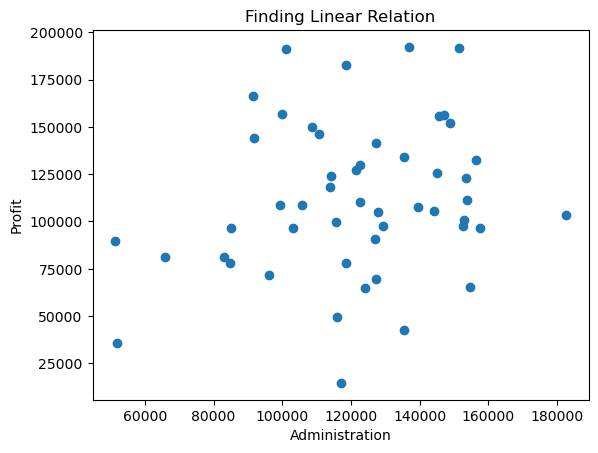

In [ ]:
x_col_name = 'Administration'
scatter(x_col_name)

### Visualizing Histograms (Frequency Distribution of variables)

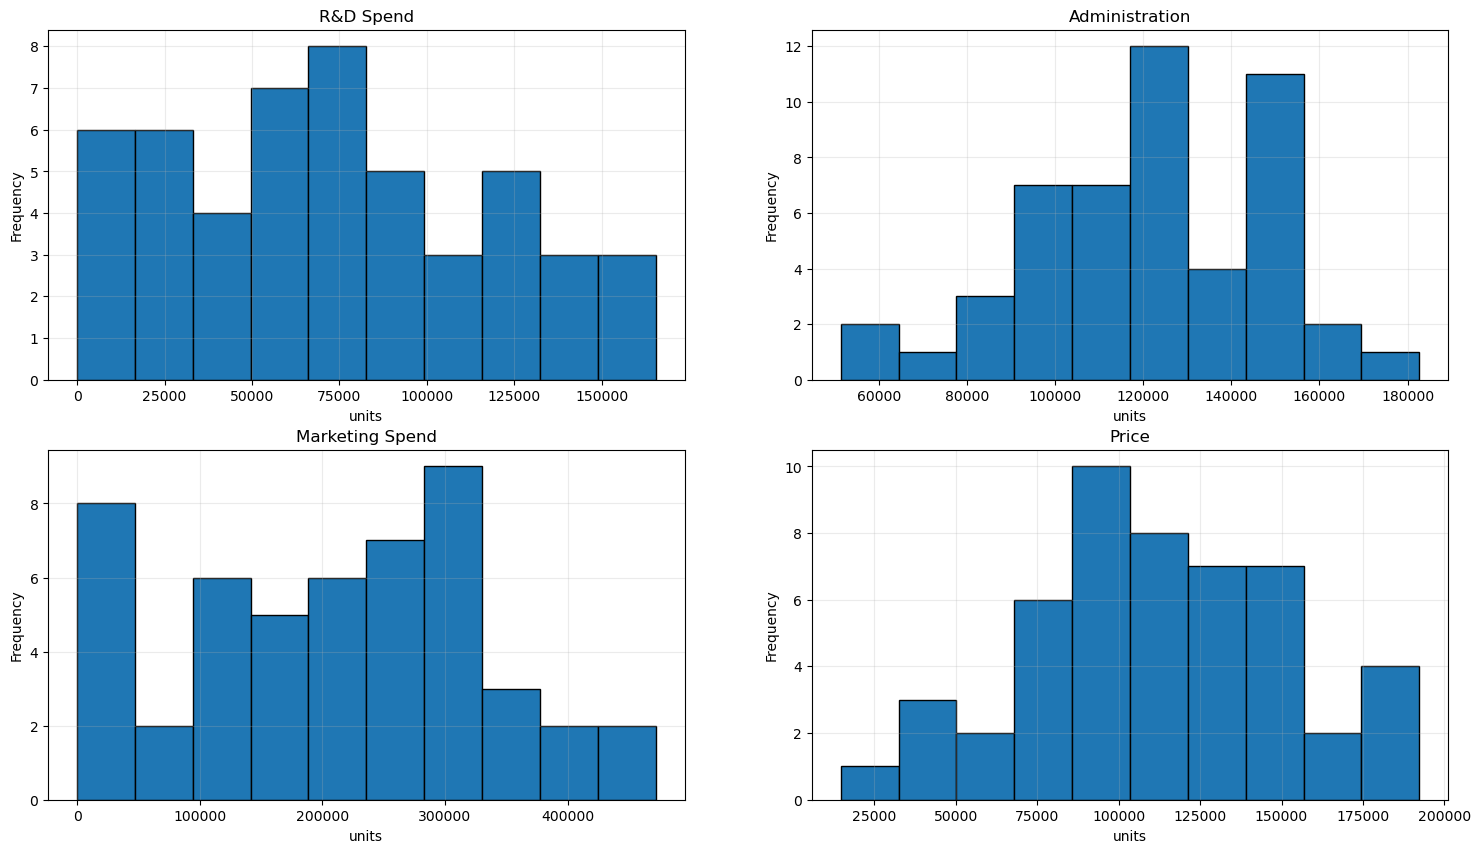

In [ ]:
# Visualise the distribution of independent and dependent variables
'''Create subplots in 2 row and 2 columns'''
fig, ax = plt.subplots(2,2)
fig.set_figheight(10)
fig.set_figwidth(20)
fig.subplots_adjust(left=.2, bottom=None, right=None, top=None, wspace=.2, hspace=.2)
plt1 = plt.subplot(2,2,1)
plt2 = plt.subplot(2,2,2)
plt3 = plt.subplot(2,2,3)
plt4 = plt.subplot(2,2,4)

plt1.hist(df.values[:,0], label='R&D Spend', edgecolor='black')
plt1.set_title('R&D Spend')
plt1.set_xlabel('units')
plt1.set_ylabel('Frequency')
plt1.grid(axis='both', alpha=.25)

plt2.hist(df.values[:,1], label='Administration', edgecolor='black')
plt2.set_title('Administration')
plt2.set_xlabel('units')
plt2.set_ylabel('Frequency')
plt2.grid(axis='both', alpha=.25)

plt3.hist(df.values[:,2], label='Marketing Spend', edgecolor='black')
plt3.set_title('Marketing Spend')
plt3.set_xlabel('units')
plt3.set_ylabel('Frequency')
plt3.grid(axis='both', alpha=.25)

plt4.hist(df.values[:,3], label='Price', edgecolor='black')
plt4.set_title('Price')
plt4.set_xlabel('units')
plt4.set_ylabel('Frequency')
plt4.grid(axis='both', alpha=.25)

### Visualizing Linearity using Scatter Plots

In [ ]:
# Visualise the linearity of independent and dependent variables using scatter plots
'''Create subplots in 2 row and 3 columns'''
def show_linearity_subplots_for(df):
    fig, ax = plt.subplots(1,3)
    fig.set_figheight(5)
    fig.set_figwidth(20)
    fig.subplots_adjust(left=.2, bottom=None, right=None, top=None, wspace=.2, hspace=.2)
    plt1 = plt.subplot(1,3,1)
    plt2 = plt.subplot(1,3,2)
    plt3 = plt.subplot(1,3,3)

    plt1.scatter(df[df.columns[0]], df[df.columns[3]])
    plt1.set_xlabel(df.columns[0])
    plt1.set_ylabel(df.columns[3])
    plt1.grid(axis='both', alpha=.25)

    plt2.scatter(df[df.columns[1]], df[df.columns[3]])
    plt2.set_xlabel(df.columns[1])
    plt2.set_ylabel(df.columns[3])
    plt2.grid(axis='both', alpha=.25)

    plt3.scatter(df[df.columns[2]], df[df.columns[3]])
    plt3.set_xlabel(df.columns[2])
    plt3.set_ylabel(df.columns[3])
    plt3.grid(axis='both', alpha=.25)

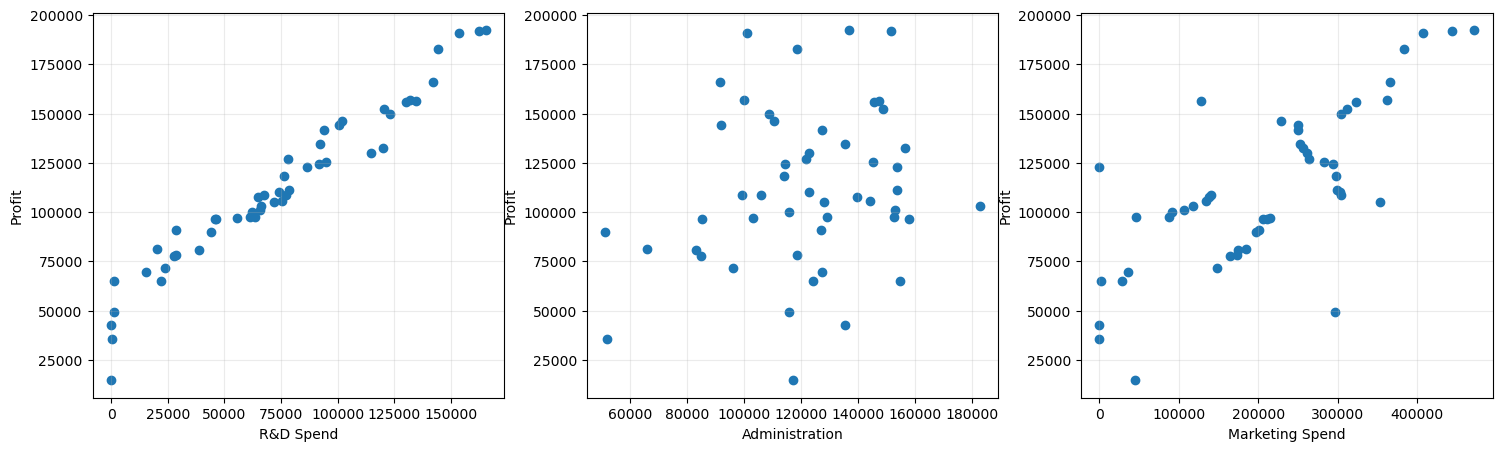

In [ ]:
show_linearity_subplots_for(df)

As we can see, `Profit` is linearly dependent on all the independent variables we selected. We can however notice that the scales represented on the X-axis are all different than each other. So before going on with our models, we need to normalize our data values (centering data values towards 0)

## Data Normalization

In [ ]:
df_norm = (df-np.mean(df, axis = 0))/np.std(df, axis = 0)

In [ ]:
df_norm.head()

,R&D Spend,Administration,Marketing Spend,Profit
0,2.016411,0.560753,2.153943,2.011203
1,1.955860,1.082807,1.923600,1.999430
2,1.754364,-0.728257,1.626528,1.980842
3,1.554784,-0.096365,1.422210,1.776627
4,1.504937,-1.079919,1.281528,1.357740


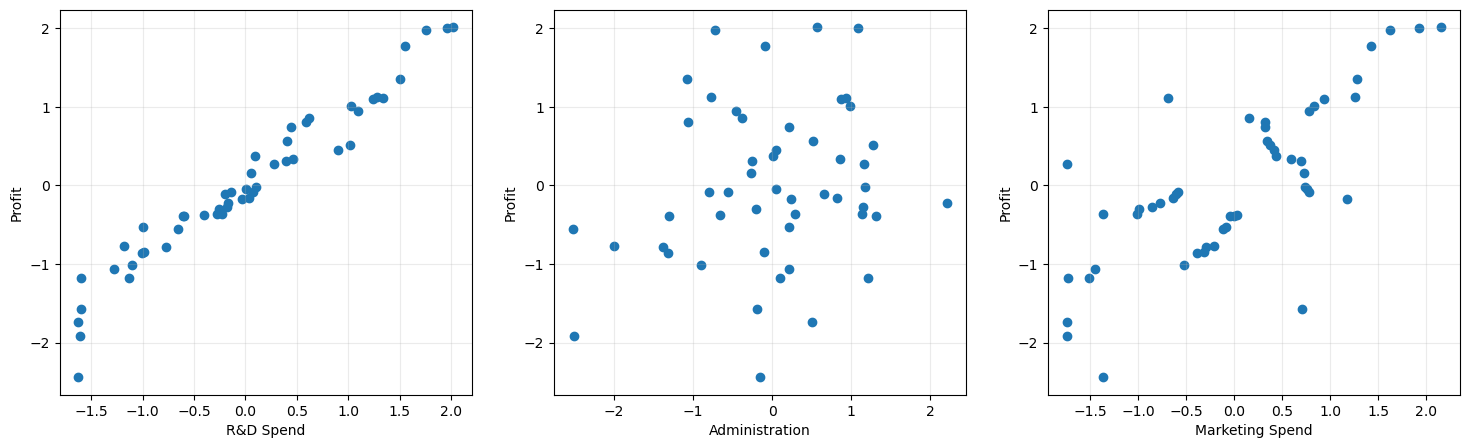

In [ ]:
show_linearity_subplots_for(df_norm)

The plot doesn't seem to vary much but what we can observe that the scales now are constant, and all the data points are centered around zero.

# Generation of Heat Map for correlation analysis
We will be employing the seaborn library for this.

<Axes: >

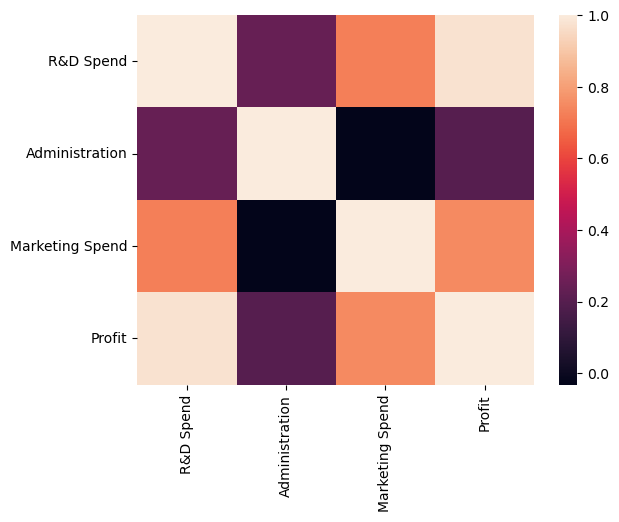

In [ ]:
# Visualise the correlation between independent and dependent variables using Heat Map
sns.heatmap(df.corr())

From the above plot it is evident that 'Profit' has higher correlation with 'R&D Speed', followed by 'Marketing Spend' and least correlated with 'Administration'